<center><h1>Magdum_Seona_HW7</h1></center>

Name: Seona Magdum
<br>
Github Username: seo2003
<br>
USC ID: 6077378254

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, hamming_loss, silhouette_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV


### (a) Download the Anuran Calls (MFCCs) Data Set

In [38]:
data = pd.read_csv("../data/Frogs_MFCCs.csv")

train_data, test_data = train_test_split(
    data,
    train_size=0.70,
    random_state=42
)

print("Training set:", train_data.shape)
print("Testing set:", test_data.shape)

Training set: (5036, 26)
Testing set: (2159, 26)


### (b) Train a classifier for each label

#### (i) Research

An Exact Match evaluation methods c hecks whether all three predicted labels exactly match the actual labels for an observation. In this case it will check if Family, Genus, and Species are predicted correctly. If even one label is incorrect, the entire observation is counted as incorrect. Hamming Loss measures the fraction of individual labels that are incorrectly predicted. A lower Hamming Loss is better, while Hamming Score being higher is better. The Hamming score measures the fraction of labels predicted correctly and is calculated as 1 minus Hamming Loss.

#### (ii) Train a SVM for each of the labels

In [39]:
#features and labels
X_train = train_data.drop(columns=['Family', 'Genus', 'Species'])
y_train = train_data[['Family', 'Genus', 'Species']]

X_test = test_data.drop(columns=['Family', 'Genus', 'Species'])
y_test = test_data[['Family', 'Genus', 'Species']]

labels = ['Family', 'Genus', 'Species']

#parameter grid
param_grid = {
    'estimator__C': [0.1, 1, 10, 100],
    'estimator__gamma': [0.001, 0.01, 0.1, 1]
}

#train
raw_results = {}
for label in labels:
    svm = OneVsRestClassifier(SVC(kernel='rbf'))
    grid = GridSearchCV(
        svm,
        param_grid,
        cv=10,
        scoring='accuracy',
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])
    predictions = grid.predict(X_test)

    raw_results[label] = {
        'best parameters': grid.best_params_,
        'CV Accuracy': grid.best_score_,
        'test accuracy': accuracy_score(y_test[label], predictions)
    }

    print("\nRaw Attributes -", label)
    print("best parameters:", grid.best_params_)
    print("CV accuracy:", grid.best_score_)
    print("test accuracy:", accuracy_score(y_test[label], predictions))

#train using standardized attributes
standardized_results = {}
for label in labels:
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', OneVsRestClassifier(SVC(kernel='rbf')))
    ])

    standardized_grid = {
        'svm__estimator__C': [0.1, 1, 10, 100],
        'svm__estimator__gamma': [0.001, 0.01, 0.1, 1]
    }

    grid = GridSearchCV(
        pipeline,
        standardized_grid,
        cv=10,
        scoring='accuracy',
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])
    predictions = grid.predict(X_test)
    standardized_results[label] = {
        'best parameters': grid.best_params_,
        'CV Accuracy': grid.best_score_,
        'test accuracy': accuracy_score(y_test[label], predictions)
    }

    print("\nStandardized Attributes -", label)
    print("best parameters:", grid.best_params_)
    print("CV accuracy:", grid.best_score_)
    print("test accuracy:", accuracy_score(y_test[label], predictions))


# Compare results
print("\nRaw attributes results")
print(pd.DataFrame(raw_results).T)

print("\nStandardized attributres results")
print(pd.DataFrame(standardized_results).T)



Raw Attributes - Family
best parameters: {'estimator__C': 1, 'estimator__gamma': 0.1}
CV accuracy: 1.0
test accuracy: 0.999536822603057

Raw Attributes - Genus
best parameters: {'estimator__C': 1, 'estimator__gamma': 0.1}
CV accuracy: 1.0
test accuracy: 0.999536822603057

Raw Attributes - Species
best parameters: {'estimator__C': 1, 'estimator__gamma': 0.1}
CV accuracy: 1.0
test accuracy: 0.999536822603057

Standardized Attributes - Family
best parameters: {'svm__estimator__C': 100, 'svm__estimator__gamma': 0.01}
CV accuracy: 0.9938448673041117
test accuracy: 0.9962945808244558

Standardized Attributes - Genus
best parameters: {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.01}
CV accuracy: 0.9934472529899965
test accuracy: 0.9925891616489115

Standardized Attributes - Species
best parameters: {'svm__estimator__C': 100, 'svm__estimator__gamma': 0.01}
CV accuracy: 0.9930488497585912
test accuracy: 0.9935155164427976

Raw attributes results
                                      bes

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [40]:
#separate features and labels
X_train = train_data.drop(columns=['Family', 'Genus', 'Species'])
y_train = train_data[['Family', 'Genus', 'Species']]
X_test = test_data.drop(columns=['Family', 'Genus', 'Species'])
y_test = test_data[['Family', 'Genus', 'Species']]
labels = ['Family', 'Genus', 'Species']

#L1-penalized SVM
param_grid = {
    'svm__estimator__C': [0.001, 0.01, 0.1, 1, 10, 100]
}

results = {}
for label in labels:
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', OneVsRestClassifier(
            LinearSVC(penalty='l1', dual=False, max_iter=500000, tol=0.001)
        ))
    ])

    grid = GridSearchCV(
        pipeline,
        param_grid,
        cv=10,
        scoring='accuracy',
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])
    predictions = grid.predict(X_test)
    results[label] = {
        'best C value': grid.best_params_,
        'CV Accuracy': grid.best_score_,
        'test Accuracy': accuracy_score(y_test[label], predictions)
    }

    print("\n", label)
    print("best C: value", grid.best_params_)
    print("CV accuracy:", grid.best_score_)
    print("test accuracy:", accuracy_score(y_test[label], predictions))

print("\nL1-Penalized SVM Results")
print(pd.DataFrame(results).T)



 Family
best C: value {'svm__estimator__C': 100}
CV accuracy: 0.9694199880084572
test accuracy: 0.9629458082445577

 Genus
best C: value {'svm__estimator__C': 10}
CV accuracy: 0.983122692416927
test accuracy: 0.9828624363131079

 Species
best C: value {'svm__estimator__C': 10}
CV accuracy: 0.9831222979582822
test accuracy: 0.98471514590088

L1-Penalized SVM Results
                       best C value CV Accuracy test Accuracy
Family   {'svm__estimator__C': 100}     0.96942      0.962946
Genus     {'svm__estimator__C': 10}    0.983123      0.982862
Species   {'svm__estimator__C': 10}    0.983122      0.984715


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [41]:
!pip install imbalanced-learn

In [42]:


X_train = train_data.drop(columns=['Family', 'Genus', 'Species'])
y_train = train_data[['Family', 'Genus', 'Species']]
X_test = test_data.drop(columns=['Family', 'Genus', 'Species'])
y_test = test_data[['Family', 'Genus', 'Species']]

labels = ['Family', 'Genus', 'Species']
results = {}
predictions = pd.DataFrame(index=y_test.index)

for label in labels:
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('svm', LinearSVC(penalty='l1', dual=False, max_iter=100000))
    ])

    param_grid = {'svm__C': [0.001, 0.01, 0.1, 1, 10, 100]}

    grid = GridSearchCV(pipeline, param_grid, cv=10,
                        scoring='accuracy', n_jobs=-1)
    grid.fit(X_train, y_train[label])

    predictions[label] = grid.predict(X_test)
    results[label] = {
        'Best C': grid.best_params_['svm__C'],
        'CV Accuracy': grid.best_score_,
        'Test Accuracy': accuracy_score(y_test[label], predictions[label])
    }

pred = pd.DataFrame(predictions, index=y_test.index)

print("Exact Match:", (y_test == pred).all(axis=1).mean())
print("Hamming Loss:", (y_test != pred).to_numpy().mean())
print("Hamming Score:", 1 - (y_test != pred).to_numpy().mean())


Exact Match: 0.9346919870310328
Hamming Loss: 0.032268025320364366
Hamming Score: 0.9677319746796357


The model achieved an exact match of 93.46%, meaning all three Family, Genus, and Species were correctly predicted for 93.46% of observations. The Hamming Loss was 3.22%, meaning that only a small percentage of individual label predictions were incorrect. The Hamming Score was 96.77%, showing that the model correctly predicted approximately 96.77% of individual labels. Overall, the results indicate strong classification performance.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [43]:
# Separate features and true labels
X = data.drop(columns=['Family', 'Genus', 'Species', 'RecordID'])
y = data[['Family', 'Genus', 'Species']]

#standardize features
X_scaled = StandardScaler().fit_transform(X)

#select best k 
scores = {}
for k in range(2, 51):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    clusters = km.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, clusters)

best_k = max(scores, key=scores.get)
print("Best k:", best_k)

# k means 50 times and Hamming distance
hamming_distances = []
for i in range(50):
    km = KMeans(n_clusters=best_k, random_state=i, n_init=10)
    clusters = km.fit_predict(X_scaled)

    predictions = pd.DataFrame(index=data.index)

    for label in ['Family', 'Genus', 'Species']:
        mapping = {}
        for cluster in range(best_k):
            mask = clusters == cluster
            if mask.sum() > 0:
                mapping[cluster] = y.loc[mask, label].mode()[0]

        predictions[label] = pd.Series(clusters, index=data.index).map(mapping)

    #Hamming distance
    distance = (predictions.values != y.values).mean()
    hamming_distances.append(distance)

print("Average Hamming Distance:", np.mean(hamming_distances))
print("Standard Deviation:", np.std(hamming_distances))


Best k: 4
Average Hamming Distance: 0.24478943710910359
Standard Deviation: 0.011743206969612566


### (b) Determine which family is the majority

In [44]:
#clusters using the selected k = 4
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10, max_iter=500)
clusters = kmeans.fit_predict(X_scaled)
cluster_data = data.copy()
cluster_data['Cluster'] = clusters

#print majoriry labels in each cluster
for label in ['Family', 'Genus', 'Species']:
    print("\nMajority", label)
    print(cluster_data.groupby('Cluster')[label].agg(lambda x: x.value_counts().idxmax()))



Majority Family
Cluster
0            Hylidae
1    Leptodactylidae
2            Hylidae
3    Leptodactylidae
Name: Family, dtype: object

Majority Genus
Cluster
0    Hypsiboas
1    Adenomera
2    Hypsiboas
3    Adenomera
Name: Genus, dtype: object

Majority Species
Cluster
0         HypsiboasCordobae
1    AdenomeraHylaedactylus
2      HypsiboasCinerascens
3            AdenomeraAndre
Name: Species, dtype: object


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [45]:
#labels
labels = ['Family', 'Genus', 'Species']
cluster_data = data[labels].copy()
cluster_data['Cluster'] = clusters

majority = cluster_data.groupby('Cluster')[labels].agg(lambda x: x.mode().iloc[0])
predictions = pd.DataFrame([majority.loc[c].values for c in clusters], columns=labels)
y_true = data[labels].reset_index(drop=True)

h_loss = np.mean(y_true.values != predictions.values)

#print
print("Hamming Distance:", h_loss)
print("Hamming Score:", 1 - h_loss)
print("Hamming Loss:", h_loss)

Hamming Distance: 0.2326152420662497
Hamming Score: 0.7673847579337503
Hamming Loss: 0.2326152420662497


## 3. ISLR 12.6.2

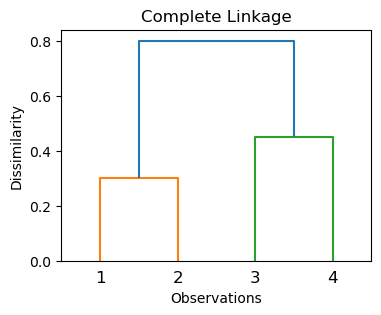

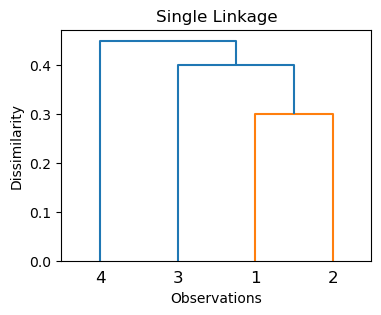

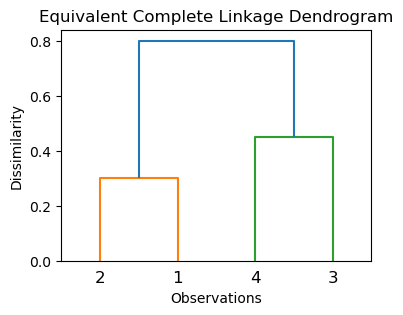

In [46]:

D = np.array([
    [0, 0.3, 0.4, 0.7],
    [0.3, 0, 0.5, 0.8],
    [0.4, 0.5, 0, 0.45],
    [0.7, 0.8, 0.45, 0]
])

distances = squareform(D)

#a) sketching the dendogram
complete = linkage(distances, method='complete')
plt.figure(figsize=(4, 3))
dendrogram(complete, labels=['1', '2', '3', '4'])
plt.title('Complete Linkage')
plt.xlabel('Observations')
plt.ylabel('Dissimilarity')
plt.show()

#b)single linkage
single = linkage(distances, method='single')
plt.figure(figsize=(4, 3))
dendrogram(single, labels=['1', '2', '3', '4'])
plt.title('Single Linkage')
plt.xlabel('Observations')
plt.ylabel('Dissimilarity')
plt.show()

#e) Equivalent complete linkage dendrogram
plt.figure(figsize=(4, 3))
dendrogram(complete, labels=['2', '1', '4', '3'])
plt.title('Equivalent Complete Linkage Dendrogram')
plt.xlabel('Observations')
plt.ylabel('Dissimilarity')
plt.show()

Complete linkage (part a) merges observations 1 and 2 at 0.30, observations 3 and 4 at 0.45, and both clusters at 0.80. Single linkage (part b) merges 1 and 2 at 0.30, 3 to 0.40, and 4 at 0.45. With two clusters, complete linkage gives 2 and 4, while single linkage gives 3 and 4. An equivalent complete linkage to part a can be made by swapping the leaf positions and kept the same fusion heights.